In [3]:

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

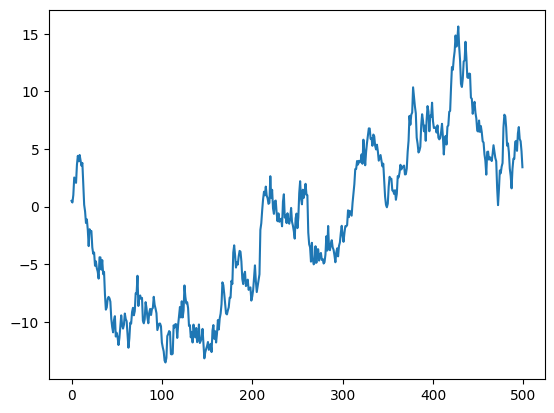

In [ ]:
np.random.seed(42)
steps = np.random.standard_normal(500)
rw = np.cumsum(steps)
plt.plot(rw)

In [11]:
rw = pd.DataFrame({'value': rw})

In [6]:
from statsmodels.tsa.stattools import adfuller 
adf = adfuller(rw)
print(f"ADF: {adf[0]}, p-value: {adf[1]}")

ADF: -1.4986304785036462, p-value: 0.5341887124972032


In [8]:
rw_diff = np.diff(rw)
adf = adfuller(rw_diff)
print(f"ADF: {adf[0]}, p-value: {adf[1]}")

ADF: -22.313025583815012, p-value: 0.0


In [12]:
train, test = rw[:700], rw[700:]


In [18]:
pmean = np.mean(train)
pmed = np.median(train)
rw.last_value = rw.shift(1)
rw.loc[:, "pmean"] = pmean
rw.loc[:, "pmed"] = pmed

/var/folders/hv/y00c8cl91z34xlwn9xbh5cfr0000gn/T/ipykernel_21236/1560340988.py:3: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  rw.last_value = rw.shift(1)


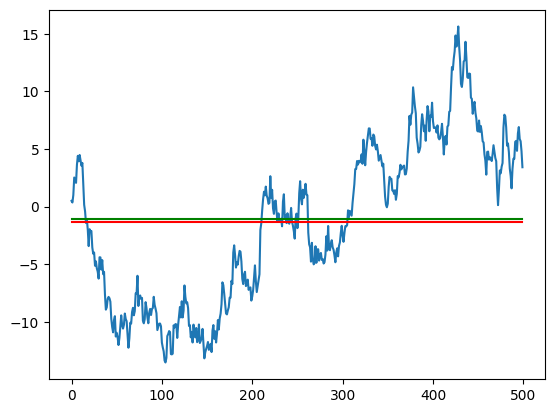

In [23]:
plt.plot(rw.value)
plt.plot(rw.pmean, 'r-')
plt.plot(rw.pmed, 'g-')